# 02 - Pipeline de Dataset: Calibración Espacial de Interfaz (UI Layout)

Pipeline modular de **Calibración Espacial de UI** para Clash Royale.  
Aprovecha los segmentos temporales obtenidos en el Notebook 01 (`metadata/segmented_matches.json`) para capturar un fotograma en un segundo seguro de gameplay confirmado ($t_{\text{start}} + 8\text{ s}$) y determinar con precisión matemática las coordenadas canónicas de:

1. **Arena de batalla** (`arena_box`): cuadrícula jugable de combate (desde justo debajo del HUD superior abarcando torres de princesas enemigas hasta la base del rey propio, excluyendo arbustos y tejados decorativos).
2. **Barra y número de elixir** (`elixir_bar_box`): ancla primaria infalible detectada por pico de densidad magenta. Incluye el número blanco de elixir (0-10), la gota y el texto 'Máx.: 10'.
3. **Los 4 slots de cartas en mano** (`card_slots`): recuadros simétricos anclados sobre la barra de elixir que incluyen el círculo inferior de coste y **margen superior de elevación** (cuando el jugador selecciona una carta con borde blanco brillante).
4. **Próxima carta** (`next_card_box`): miniatura de la siguiente carta a la izquierda.
5. **Botón de emotes** (`emote_button_box`): icono de tres puntos (...). La oclusión por emotes se detecta directamente sobre los 4 slots de cartas (al abrirse el menú de chat, un panel azul con frases cubre el 100% de la mano).

### Resiliencia y Persistencia Atómica en Cloudflare R2 (API S3):
- Checkpointing atómico por video en `metadata/layouts/<video_id>.json`.
- Manifiesto consolidado maestro en `metadata/ui_layouts.json`.
- Idempotencia (`SKIP_ALREADY_PROCESSED = True`): salta videos ya calibrados en 0 segundos.
- **Galería visual de comprobación:** dibuja sobre cada video las cajas de colores para inspección humana instantánea.

In [40]:
# Dependencias esenciales: opencv-python, pillow, requests, boto3
# En Kaggle, requests, pillow y boto3 ya están disponibles.
# Si estás en un entorno limpio sin boto3 u opencv, descomenta:
# !pip install -q boto3 opencv-python pillow requests


In [41]:
import os, sys, json, time, re
from pathlib import Path
import requests
import cv2
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import boto3
from botocore.config import Config

# 1. Directorios de trabajo
WORK_DIR = Path('/kaggle/working') if Path('/kaggle').exists() else Path('data')
VIDEOS_DIR = WORK_DIR / 'videos'
LAYOUTS_DIR = WORK_DIR / 'layouts'
MANIFESTS_DIR = WORK_DIR / 'manifests'

for d in [VIDEOS_DIR, LAYOUTS_DIR, MANIFESTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 2. Helper de configuración híbrida (Kaggle Secrets + Variables de Entorno / .env)
def get_config(key: str, default: str = None) -> str:
    try:
        from kaggle_secrets import UserSecretsClient
        val = UserSecretsClient().get_secret(key)
        if val:
            return val
    except Exception:
        pass
    return os.getenv(key, default)

def fmt_time(seconds: int) -> str:
    if not seconds:
        return "0:00"
    m, s = divmod(int(seconds), 60)
    h, m = divmod(m, 60)
    return f"{h}:{m:02d}:{s:02d}" if h else f"{m}:{s:02d}"

gallery_previews = []
processed_layouts = {}
print(f"✔ Directorio de trabajo: {WORK_DIR}")


✔ Directorio de trabajo: /kaggle/working


In [42]:
# Conexión a Cloudflare R2 y carga de videos segmentados (Notebook 01)

ADMIN_TOKEN = get_config('ADMIN_TOKEN')
ANNOTATOR_BASE = get_config('ANNOTATOR_URL', 'https://cr-dataset.eddux.dev').rstrip('/')
CDN_BASE = get_config('CDN_URL', 'https://cdn-cr.eddux.dev').rstrip('/')

R2_ENDPOINT = get_config('R2_ENDPOINT')
R2_ACCESS_KEY = get_config('R2_ACCESS_KEY')
R2_SECRET_KEY = get_config('R2_SECRET_KEY')
R2_BUCKET = get_config('R2_BUCKET', 'cr-videos')

s3_client = None
if R2_ENDPOINT and R2_ACCESS_KEY and R2_SECRET_KEY:
    try:
        s3_client = boto3.client(
            's3',
            endpoint_url=R2_ENDPOINT,
            aws_access_key_id=R2_ACCESS_KEY,
            aws_secret_access_key=R2_SECRET_KEY,
            config=Config(signature_version='s3v4')
        )
        print(f"✔ Conectado a Cloudflare R2 vía S3 API (Bucket: '{R2_BUCKET}')")
    except Exception as e:
        print(f"⚠ Error conectando a R2: {e}")
else:
    print("ℹ Modo local: credenciales de R2 no configuradas.")

# 1. Obtener el manifiesto de partidas segmentadas (Notebook 01)
segmented_manifest = None
manifest_path = MANIFESTS_DIR / 'segmented_matches.json'

if s3_client:
    try:
        obj = s3_client.get_object(Bucket=R2_BUCKET, Key='metadata/segmented_matches.json')
        segmented_manifest = json.loads(obj['Body'].read().decode('utf-8'))
        with open(manifest_path, 'w', encoding='utf-8') as f:
            json.dump(segmented_manifest, f, indent=2, ensure_ascii=False)
        print(f"✔ Manifiesto de segmentaciones cargado desde R2 ({len(segmented_manifest.get('videos', {}))} videos disponibles)")
    except Exception as e:
        print(f"⚠ No se pudo leer metadata/segmented_matches.json desde R2: {e}")

if not segmented_manifest and manifest_path.exists():
    with open(manifest_path, 'r', encoding='utf-8') as f:
        segmented_manifest = json.load(f)
    print(f"✔ Manifiesto de segmentaciones cargado desde disco local")

# 2. Detección de layouts ya calibrados previamente (Idempotencia)
def get_processed_layout_ids():
    processed = set()
    for f in LAYOUTS_DIR.glob('*.json'):
        processed.add(f.stem)
    if s3_client:
        try:
            res = s3_client.list_objects_v2(Bucket=R2_BUCKET, Prefix='metadata/layouts/')
            for item in res.get('Contents', []):
                vid = Path(item['Key']).stem
                if vid:
                    processed.add(vid)
        except Exception as e:
            print(f"⚠ Error consultando layouts en R2: {e}")
    return processed

already_calibrated = get_processed_layout_ids()
print(f"✔ Layouts ya calibrados previamente: {len(already_calibrated)}")

# =========================================================================
# CONFIGURACIÓN DE SELECCIÓN DE VIDEOS
# Opciones: 'all', número entero (ej. 5), o lista ['id1', 'id2']
# =========================================================================
VIDEO_FILTER = 'all'

videos_dict = segmented_manifest.get('videos', {}) if segmented_manifest else {}
video_ids_list = list(videos_dict.keys())

if VIDEO_FILTER == 'all':
    target_video_ids = video_ids_list
elif isinstance(VIDEO_FILTER, int):
    target_video_ids = video_ids_list[:VIDEO_FILTER]
elif isinstance(VIDEO_FILTER, str):
    target_video_ids = [VIDEO_FILTER] if VIDEO_FILTER in videos_dict else []
elif isinstance(VIDEO_FILTER, (list, tuple, set)):
    target_video_ids = [vid for vid in VIDEO_FILTER if vid in videos_dict]
else:
    target_video_ids = video_ids_list

pending = sum(1 for vid in target_video_ids if vid not in already_calibrated)
print(f"✔ Videos seleccionados: {len(target_video_ids)} (Pendientes por calibrar: {pending})")


✔ Conectado a Cloudflare R2 vía S3 API (Bucket: 'cr-videos')
✔ Manifiesto de segmentaciones cargado desde R2 (17 videos disponibles)
✔ Layouts ya calibrados previamente: 18
✔ Videos seleccionados: 17 (Pendientes por calibrar: 0)


In [43]:
# Utilidades de extracción de fotogramas, guardado atómico y consolidación

def fetch_gameplay_frame(video_id: str, sample_sec: int = 15) -> tuple[np.ndarray, Path]:
    """
    Extrae el fotograma de gameplay en el segundo indicado.
    Intenta lectura directa vía HTTP si OpenCV lo soporta, o descarga el archivo temporalmente.
    Retorna: (frame_rgb, local_video_path_or_None)
    """
    target = VIDEOS_DIR / f"{video_id}.mp4"
    url = f"{CDN_BASE}/videos/{video_id}.mp4"
    downloaded_path = None
    
    # 1. Si no existe localmente, descargamos con streaming
    if not target.exists() or target.stat().st_size < 1024 * 1024:
        t0 = time.time()
        req_headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
        try:
            with requests.get(url, headers=req_headers, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(target, 'wb') as f:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk)
            downloaded_path = target
            mb = target.stat().st_size / (1024 * 1024)
            print(f"  ✔ {video_id} descargado ({mb:.1f} MB en {time.time()-t0:.1f}s)", flush=True)
        except Exception as e:
            print(f"  ❌ Error descargando {video_id}: {e}", flush=True)
            return None, None
    else:
        downloaded_path = None # ya existía previamente
        
    # 2. Extraer fotograma con OpenCV
    cap = cv2.VideoCapture(str(target))
    if not cap.isOpened():
        print(f"  ❌ No se pudo abrir video {target}", flush=True)
        return None, downloaded_path
        
    cap.set(cv2.CAP_PROP_POS_MSEC, sample_sec * 1000)
    ret, frame_bgr = cap.read()
    cap.release()
    
    if not ret or frame_bgr is None:
        print(f"  ❌ Error extrayendo frame en {sample_sec}s para {video_id}", flush=True)
        return None, downloaded_path
        
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    return frame_rgb, downloaded_path

def save_layout_checkpoint(layout_data: dict):
    """Guarda el JSON de calibración en disco y lo respalda atómicamente en Cloudflare R2."""
    vid = layout_data['video_id']
    local_path = LAYOUTS_DIR / f"{vid}.json"
    with open(local_path, 'w', encoding='utf-8') as f:
        json.dump(layout_data, f, indent=2, ensure_ascii=False)
        
    if s3_client:
        try:
            s3_key = f"metadata/layouts/{vid}.json"
            s3_client.put_object(
                Bucket=R2_BUCKET,
                Key=s3_key,
                Body=json.dumps(layout_data, indent=2, ensure_ascii=False).encode('utf-8'),
                ContentType='application/json'
            )
            print(f"  ☁ [{vid}] Layout respaldado en R2 ({s3_key})", flush=True)
        except Exception as e:
            print(f"  ⚠ Error subiendo layout de {vid} a R2: {e}", flush=True)

def consolidate_layouts_manifest():
    """Consolida todos los layouts individuales en metadata/ui_layouts.json."""
    all_layouts = {}
    for f in LAYOUTS_DIR.glob('*.json'):
        try:
            with open(f, 'r', encoding='utf-8') as jf:
                d = json.load(jf)
                all_layouts[d['video_id']] = d
        except Exception:
            pass
            
    if s3_client:
        try:
            res = s3_client.list_objects_v2(Bucket=R2_BUCKET, Prefix='metadata/layouts/')
            for item in res.get('Contents', []):
                vid = Path(item['Key']).stem
                if vid and vid not in all_layouts:
                    obj = s3_client.get_object(Bucket=R2_BUCKET, Key=item['Key'])
                    all_layouts[vid] = json.loads(obj['Body'].read().decode('utf-8'))
        except Exception as e:
            print(f"⚠ Error leyendo layouts de R2: {e}")
            
    manifest = {
        'updated_at': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
        'total_calibrated_videos': len(all_layouts),
        'layouts': all_layouts
    }
    
    local_manifest = MANIFESTS_DIR / 'ui_layouts.json'
    with open(local_manifest, 'w', encoding='utf-8') as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
        
    if s3_client:
        try:
            s3_client.put_object(
                Bucket=R2_BUCKET,
                Key='metadata/ui_layouts.json',
                Body=json.dumps(manifest, indent=2, ensure_ascii=False).encode('utf-8'),
                ContentType='application/json'
            )
            print(f"\n☁ Manifiesto consolidado de layouts actualizado en R2: metadata/ui_layouts.json ({len(all_layouts)} videos)", flush=True)
        except Exception as e:
            print(f"⚠ Error subiendo ui_layouts.json a R2: {e}")
            
    return manifest


In [44]:
# =========================================================================
# ALGORITMO DE CALIBRACIÓN ESPACIAL DE UI (AFINADO Y BLINDADO)
# - Detección automática de pillarbox (bandas negras laterales si las hubiera)
# - ANCLAJE INFALIBLE DE ELIXIR: Pico de densidad magenta en el 15% inferior de la pantalla.
#   Funciona con cualquier nivel de elixir (incluso con 1 o 2 de elixir), inmune a los círculos de coste.
# - Cobertura total de la caja de elixir: abarca número superior (0-10), gota, barra y Máx.: 10.
# - Posicionamiento canónico estricto de los 4 slots de cartas (ancho 0.18*gw, alto 0.24*gw)
#   con margen superior de elevación de selección y margen inferior para el círculo de coste.
# - Próxima carta y botón de emotes en la columna izquierda.
# - Cuadrícula jugable de la arena: desde justo debajo del HUD superior abarcando las torres enemigas
#   hasta justo detrás de la base del rey propio (donde acaban los cuadrados de piedra).
# =========================================================================

def calibrate_ui_layout(frame_rgb: np.ndarray, video_id: str = "") -> dict:
    h, w = frame_rgb.shape[:2]
    aspect = w / h
    
    # 1. Detección de bordes negros laterales (Pillarbox)
    left_strip = frame_rgb[int(h * 0.3):int(h * 0.7), :int(w * 0.08), :].mean()
    right_strip = frame_rgb[int(h * 0.3):int(h * 0.7), int(w * 0.92):, :].mean()
    if left_strip < 15 and right_strip < 15:
        mid_row = frame_rgb[int(h * 0.5), :, :].mean(axis=-1)
        game_xs = np.where(mid_row > 25)[0]
        if len(game_xs) > 0:
            gx_min, gx_max = int(game_xs.min()), int(game_xs.max())
            gw = gx_max - gx_min
        else:
            gx_min, gw = 0, w
    else:
        gx_min, gw = 0, w
        
    # 2. ANCLAJE DE ELIXIR: Pico de densidad magenta en el 15% inferior de la pantalla
    y_start = int(h * 0.85)
    counts = []
    for y in range(y_start, h):
        row = frame_rgb[y, gx_min:gx_min+gw, :]
        mag = (row[:, 0] > 165) & (row[:, 2] > 155) & (row[:, 1] < 95) & (row[:, 0] - row[:, 1] > 60)
        counts.append(mag.sum())
        
    counts = np.array(counts)
    peak_idx = int(np.argmax(counts))
    max_c = counts[peak_idx]
    
    if max_c > 35:
        peak_y = y_start + peak_idx
    else:
        peak_y = int(h * 0.965) if aspect < 0.49 else int(h * 0.982)
        
    # Región completa de la barra de elixir (número superior, gota, barra y Máx.: 10)
    elixir_top = peak_y - int(gw * 0.046)
    elixir_bottom = min(h, peak_y + int(gw * 0.020))
    elixir_h = elixir_bottom - elixir_top
    elixir_box = [gx_min + int(gw * 0.05), elixir_top, int(gw * 0.93), elixir_h]
    
    # 3. LOS 4 SLOTS DE CARTAS EN MANO (Anclados estrictamente sobre elixir_top)
    slot_bottom_y = elixir_top
    card_h = int(gw * 0.240) # Carta, coste inferior y margen superior de elevación
    slot_top_y = slot_bottom_y - card_h
    
    card_w = int(gw * 0.180)
    gap = int(gw * 0.016)
    hand_left = gx_min + int(gw * 0.205)
    
    card_slots = []
    for i in range(4):
        sx = hand_left + i * (card_w + gap)
        card_slots.append([sx, slot_top_y, card_w, card_h])
        
    # 4. Próxima Carta y Botón de Emotes
    next_w = int(gw * 0.135)
    next_h = int(gw * 0.150)
    next_x = gx_min + int(gw * 0.040)
    next_y = slot_bottom_y - next_h
    next_card_box = [next_x, next_y, next_w, next_h]
    
    emote_btn_w = int(gw * 0.140)
    emote_btn_h = int(gw * 0.085)
    emote_btn_x = gx_min + int(gw * 0.038)
    emote_btn_y = slot_top_y + int(gw * 0.015)
    emote_button_box = [emote_btn_x, emote_btn_y, emote_btn_w, emote_btn_h]
    
    # 5. CUADRÍCULA JUGABLE DE LA ARENA (Baldosas de combate completas)
    # Límite inferior: justo detrás de la base del rey propio (donde acaban los cuadrados)
    arena_bottom_y = slot_top_y - int(gw * 0.105)
    # Límite superior: justo debajo del HUD superior, abarcando las torres de princesas enemigas
    if aspect < 0.49: # teléfonos largos con notch
        arena_top_y = int(h * 0.115)
    else: # 16:9 estándar o bandas laterales
        arena_top_y = int(h * 0.095)
        
    arena_h = arena_bottom_y - arena_top_y
    arena_box = [gx_min + int(gw * 0.03), arena_top_y, int(gw * 0.94), arena_h]
    
    def norm_box(box):
        bx, by, bw, bh = box
        return [round(bx / w, 4), round(by / h, 4), round(bw / w, 4), round(bh / h, 4)]
        
    return {
        'video_id': video_id,
        'resolution': [w, h],
        'aspect_ratio': round(aspect, 3),
        'boxes_pixel': {
            'dock_box': [gx_min, slot_top_y, gw, h - slot_top_y],
            'arena_box': arena_box,
            'elixir_bar_box': elixir_box,
            'card_slots': card_slots,
            'next_card_box': next_card_box,
            'emote_button_box': emote_button_box
        },
        'boxes_normalized': {
            'dock_box': norm_box([gx_min, slot_top_y, gw, h - slot_top_y]),
            'arena_box': norm_box(arena_box),
            'elixir_bar_box': norm_box(elixir_box),
            'card_slots': [norm_box(s) for s in card_slots],
            'next_card_box': norm_box(next_card_box),
            'emote_button_box': norm_box(emote_button_box)
        }
    }


In [45]:
# =========================================================================
# BUCLE DE CALIBRACIÓN: VIDEO POR VIDEO CON GUARDADO ATÓMICO EN R2
# - Utiliza el segundo seguro (start_sec + 8s) de la primera partida segmentada
# - Calibra y guarda de forma inmediata el JSON en metadata/layouts/<vid>.json
# - Elimina el video .mp4 descargado para no saturar disco en Kaggle
# - Acumula miniaturas con recuadros para la galería visual limpia
# =========================================================================

SKIP_ALREADY_PROCESSED = False
DELETE_VIDEO_AFTER = True

print(f"Iniciando calibración para {len(target_video_ids)} videos seleccionados...\n", flush=True)

for v_idx, vid in enumerate(target_video_ids, 1):
    v_info = videos_dict.get(vid, {})
    v_title = v_info.get('title', '')[:40]
    matches = v_info.get('matches', [])
    
    # 1. Comprobar si ya fue calibrado previamente
    if SKIP_ALREADY_PROCESSED and vid in already_calibrated:
        local_f = LAYOUTS_DIR / f"{vid}.json"
        if local_f.exists():
            try:
                with open(local_f, 'r', encoding='utf-8') as jf:
                    data = json.load(jf)
                    processed_layouts[vid] = data
                    print(f"[{v_idx}/{len(target_video_ids)}] ⏩ {vid}: ya calibrado (omitido en 0s)", flush=True)
                    continue
            except Exception:
                pass
                
    # 2. Determinar segundo seguro de gameplay
    # Si tenemos partidas segmentadas, tomamos 8 segundos después del inicio del primer match
    if matches and len(matches) > 0:
        sample_sec = int(matches[0].get('start_sec', 0)) + 8
    else:
        sample_sec = 15 # fallback
        
    print(f"[{v_idx}/{len(target_video_ids)}] 🎯 Procesando {vid} (segundo de muestra: {sample_sec}s / {fmt_time(sample_sec)})...", flush=True)
    
    # 3. Extraer frame de gameplay
    frame_rgb, dl_path = fetch_gameplay_frame(vid, sample_sec=sample_sec)
    if frame_rgb is None:
        print(f"  ❌ Omitiendo {vid} por fallo en lectura de fotograma", flush=True)
        if dl_path and DELETE_VIDEO_AFTER and dl_path.exists():
            dl_path.unlink(missing_ok=True)
        continue
        
    # 4. Calibrar Layout Espacial
    layout = calibrate_ui_layout(frame_rgb, video_id=vid)
    layout['sample_sec'] = sample_sec
    layout['match_count'] = len(matches)
    
    # 5. Guardar checkpoint atómico local y en Cloudflare R2 vía S3
    save_layout_checkpoint(layout)
    processed_layouts[vid] = layout
    already_calibrated.add(vid)
    
    # 6. Guardar miniatura con cajas para la galería visual
    h_f, w_f = frame_rgb.shape[:2]
    scale = 800.0 / h_f
    thumb_w, thumb_h = int(w_f * scale), 800
    thumb_pil = Image.fromarray(frame_rgb).resize((thumb_w, thumb_h), Image.Resampling.BILINEAR)
    draw = ImageDraw.Draw(thumb_pil)
    
    def scale_box(b):
        return [int(b[0]*scale), int(b[1]*scale), int(b[2]*scale), int(b[3]*scale)]
        
    px = layout['boxes_pixel']
    # Cian: Arena de batalla
    ax, ay, aw, ah = scale_box(px['arena_box'])
    draw.rectangle([ax, ay, ax+aw, ay+ah], outline=(0, 255, 255), width=2)
    # Magenta: Barra y número de elixir
    ex, ey, ew, eh = scale_box(px['elixir_bar_box'])
    draw.rectangle([ex, ey, ex+ew, ey+eh], outline=(255, 0, 255), width=2)
    # Verde: 4 Slots de cartas en mano
    for s in px['card_slots']:
        sx, sy, sw, sh = scale_box(s)
        draw.rectangle([sx, sy, sx+sw, sy+sh], outline=(0, 255, 0), width=2)
    # Amarillo: Próxima carta
    nx, ny, nw, nh = scale_box(px['next_card_box'])
    draw.rectangle([nx, ny, nx+nw, ny+nh], outline=(255, 255, 0), width=2)
    # Azul: Botón de emotes
    bx, by, bw, bh = scale_box(px['emote_button_box'])
    draw.rectangle([bx, by, bx+bw, by+bh], outline=(0, 150, 255), width=2)
    
    gallery_previews.append({
        'video_id': vid,
        'resolution': f"{w_f}x{h_f}",
        'aspect_ratio': layout['aspect_ratio'],
        'sample_sec': sample_sec,
        'img': thumb_pil
    })
    
    # 7. Liberar video local
    if dl_path and DELETE_VIDEO_AFTER and dl_path.exists():
        dl_path.unlink(missing_ok=True)
        
print(f"\n✔ Bucle completado. Total layouts listos: {len(processed_layouts)}", flush=True)


Iniciando calibración para 17 videos seleccionados...

[1/17] 🎯 Procesando KcLv14GDAns (segundo de muestra: 15s / 0:15)...
  ✔ KcLv14GDAns descargado (35.8 MB en 0.2s)
  ☁ [KcLv14GDAns] Layout respaldado en R2 (metadata/layouts/KcLv14GDAns.json)
[2/17] 🎯 Procesando gditbhNtBFU (segundo de muestra: 8s / 0:08)...
  ✔ gditbhNtBFU descargado (624.9 MB en 16.5s)
  ☁ [gditbhNtBFU] Layout respaldado en R2 (metadata/layouts/gditbhNtBFU.json)
[3/17] 🎯 Procesando IZrTA60YB7I (segundo de muestra: 12s / 0:12)...
  ✔ IZrTA60YB7I descargado (667.3 MB en 10.0s)
  ☁ [IZrTA60YB7I] Layout respaldado en R2 (metadata/layouts/IZrTA60YB7I.json)
[4/17] 🎯 Procesando oVrQIR5w_t4 (segundo de muestra: 10s / 0:10)...
  ✔ oVrQIR5w_t4 descargado (59.5 MB en 0.3s)
  ☁ [oVrQIR5w_t4] Layout respaldado en R2 (metadata/layouts/oVrQIR5w_t4.json)
[5/17] 🎯 Procesando LQdXz0DvY1c (segundo de muestra: 11s / 0:11)...
  ✔ LQdXz0DvY1c descargado (56.0 MB en 2.1s)
  ☁ [LQdXz0DvY1c] Layout respaldado en R2 (metadata/layouts/LQdXz

In [46]:
# Consolidación del manifiesto maestro metadata/ui_layouts.json en R2
consolidated = consolidate_layouts_manifest()
print(f"Manifiesto consolidado listo con {consolidated.get('total_calibrated_videos', 0)} videos.")



☁ Manifiesto consolidado de layouts actualizado en R2: metadata/ui_layouts.json (18 videos)
Manifiesto consolidado listo con 18 videos.


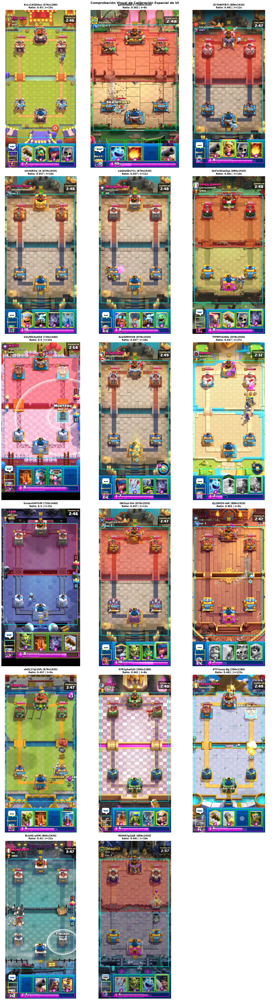

In [47]:
# =========================================================================
# GALERÍA VISUAL DE COMPROBACIÓN ESPACIAL DE UI
# Muestra cada video calibrado con sus cajas delimitadoras:
#   - Cian: Arena de batalla jugable (campo completo de combate)
#   - Verde: 4 Slots de cartas en mano (con margen de coste y elevación)
#   - Magenta: Barra y número de elixir (incluye gota y texto)
#   - Amarillo: Próxima carta
#   - Azul: Botón de emotes
# =========================================================================

if gallery_previews:
    cols = min(3, len(gallery_previews))
    rows = (len(gallery_previews) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 12 * rows))
    
    if not isinstance(axes, np.ndarray):
        axes = np.array([axes])
    axes = axes.flatten()
    
    for idx, item in enumerate(gallery_previews):
        ax = axes[idx]
        ax.imshow(item['img'])
        title_str = f"{item['video_id']} ({item['resolution']})\nRatio: {item['aspect_ratio']} | t={item['sample_sec']}s"
        ax.set_title(title_str, fontsize=12, fontweight='bold', pad=8)
        ax.axis('off')
        
    # Ocultar ejes sobrantes en la grilla
    for idx in range(len(gallery_previews), len(axes)):
        axes[idx].axis('off')
        
    plt.suptitle("Comprobación Visual de Calibración Espacial de UI", fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()
else:
    print("ℹ No se generaron nuevas miniaturas en esta sesión (los videos ya estaban previamente procesados).")
